In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import pynapple as nap
from pynwb import NWBHDF5IO

test_nwb_path = '/Volumes/INCR-NolanLab/ActiveProjects/Yiming/NWR1/processed/M01/D22/VR/sub-M01_ses-D22_typ-VR_beh.nwb'

with NWBHDF5IO(str(test_nwb_path), mode="r", load_namespaces=True) as io:
    nwbfile = io.read()
    print(nwbfile.subject.weight)

['units', 'trials', 'stationary', 'moving', 'theta', 'trial_type', 'trial_number', 'travel', 'tongue_y', 'tongue_x', 'tongue_likelihood', 'tone', 'reward_received', 'reward_failed', 'reward_available', 'nonbeaconed_total_trials', 'nonbeaconed_success', 'nonbeaconed_failure', 'lick', 'eye_y', 'eye_x', 'eye_w_y', 'eye_w_x', 'eye_w_likelihood', 'eye_sw_y', 'eye_sw_x', 'eye_sw_likelihood', 'eye_se_y', 'eye_se_x', 'eye_se_likelihood', 'eye_s_y', 'eye_s_x', 'eye_s_likelihood', 'eye_nw_y', 'eye_nw_x', 'eye_nw_likelihood', 'eye_ne_y', 'eye_ne_x', 'eye_ne_likelihood', 'eye_n_y', 'eye_n_x', 'eye_n_likelihood', 'eye_e_y', 'eye_e_x', 'eye_e_likelihood', 'eye_dilation', 'block_idx', 'beaconed_total_trials', 'beaconed_success', 'beaconed_failure', 'S', 'P']


In [55]:
results = pd.read_csv('/Volumes/INCR-NolanLab/ActiveProjects/Yiming/NWR1/analysis/glm_hmm2/M01/D24/VR/sub-M01_ses-D24_typ-VR_beh.nwb/unit_3/best_by_model.csv')

In [3]:
results

,candidate_id,model_name,n_position_basis,n_speed_basis,n_states,mean_cv_score,std_cv_score,held_out_test_score,held_out_AIC_score,n_outer_train,n_outer_test,n_design_features
0,0,position_only,6.0,NaN,2,6181.031250,1080.458789,-3646.608643,7327.217285,72211,18053,6
1,66,position_speed,6.0,4.0,2,6200.825684,1085.171639,-3638.631592,7327.263184,72211,18053,10
2,213,position_speed_trial_type,6.0,4.0,2,6204.704297,1083.059202,-3635.983643,7325.967285,72211,18053,11
3,45,position_trial_type,6.0,NaN,2,6184.616699,1078.505290,-3643.881836,7325.763672,72211,18053,7
4,24,speed_only,NaN,4.0,2,6236.972754,1149.119813,-3643.500977,7313.001953,72211,18053,4
5,360,speed_trial_type,NaN,4.0,2,6240.768555,1147.558917,-3641.184570,7312.369141,72211,18053,5
6,21,trial_type_only,NaN,NaN,2,6219.106738,1137.565834,-3643.192139,7300.384277,72211,18053,1


(-3650.0, -3600.0)

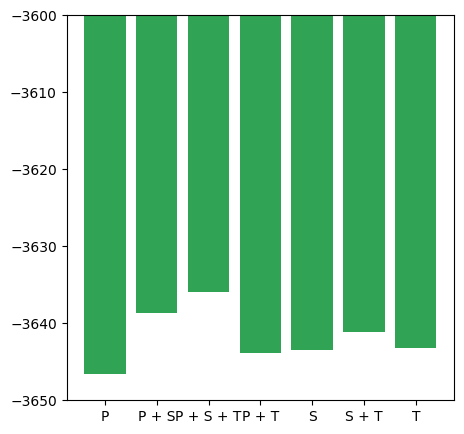

In [8]:
results_no_context = results[~results["model_name"].str.contains("context")]
fig, ax = plt.subplots(figsize=(5, 5))
plt.bar(results_no_context["model_name"], results_no_context["held_out_test_score"], color='#31a354')
xticks = ['P', 'P + S', 'P + S + T', 'P + T', 'S', 'S + T', 'T']
ax.set_xticks(range(len(xticks)))
ax.set_xticklabels(xticks, fontsize=10)
plt.ylim(-3650, -3600)
# plt.savefig('1st_year_report/glm_hmm_model_comparison.png', dpi=400)

(7200.0, 7350.0)

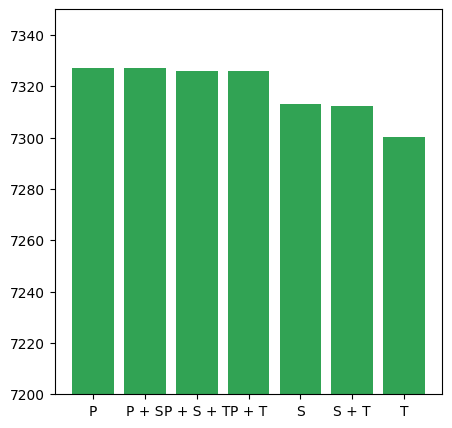

In [15]:
results_no_context = results[~results["model_name"].str.contains("context")]
fig, ax = plt.subplots(figsize=(5, 5))
plt.bar(results_no_context["model_name"], results_no_context["held_out_AIC_score"], color='#31a354')
xticks = ['P', 'P + S', 'P + S + T', 'P + T', 'S', 'S + T', 'T']
ax.set_xticks(range(len(xticks)))
ax.set_xticklabels(xticks, fontsize=10)
plt.ylim(7200, 7350)

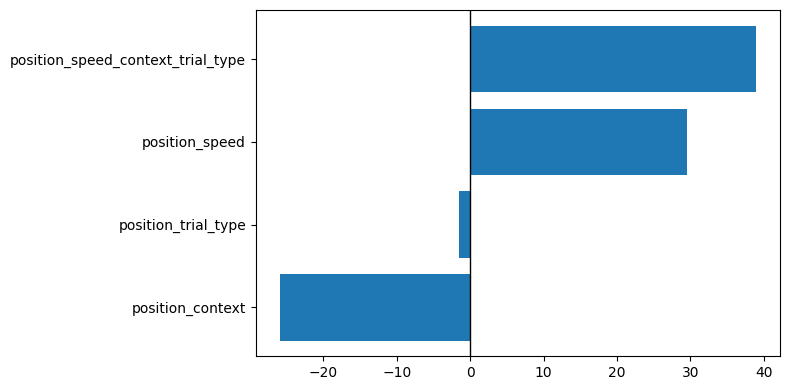

In [14]:
plot_df = results.loc[results["model_name"] != "position_only"].copy()
position_only_score = results.loc[results["model_name"] == "position_only", "held_out_test_score"].values[0]
plot_df["score_diff"] = plot_df["held_out_test_score"] - position_only_score
plot_df = plot_df.sort_values("score_diff")

plt.figure(figsize=(8, 4))
plt.barh(plot_df["model_name"], plot_df["score_diff"])
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

In [56]:
# select best model only
model_all_output = np.load('/Volumes/INCR-NolanLab/ActiveProjects/Yiming/NWR1/analysis/glm_hmm2/M01/D24/VR/sub-M01_ses-D24_typ-VR_beh.nwb/unit_3/best_model_outputs/position_speed_trial_type.npz')

In [ ]:
from pathlib import Path
nwb_path = Path('/Volumes/INCR-NolanLab/ActiveProjects/Yiming/NWR1/processed/M01/D24/VR/sub-M01_ses-D24_typ-VR_beh.nwb')

['units', 'trials', 'stationary', 'moving', 'theta', 'trial_type', 'trial_number', 'travel', 'tongue_y', 'tongue_x', 'tongue_likelihood', 'tone', 'reward_received', 'reward_failed', 'reward_available', 'nonbeaconed_total_trials', 'nonbeaconed_success', 'nonbeaconed_failure', 'lick', 'eye_y', 'eye_x', 'eye_w_y', 'eye_w_x', 'eye_w_likelihood', 'eye_sw_y', 'eye_sw_x', 'eye_sw_likelihood', 'eye_se_y', 'eye_se_x', 'eye_se_likelihood', 'eye_s_y', 'eye_s_x', 'eye_s_likelihood', 'eye_nw_y', 'eye_nw_x', 'eye_nw_likelihood', 'eye_ne_y', 'eye_ne_x', 'eye_ne_likelihood', 'eye_n_y', 'eye_n_x', 'eye_n_likelihood', 'eye_e_y', 'eye_e_x', 'eye_e_likelihood', 'eye_dilation', 'block_idx', 'beaconed_total_trials', 'beaconed_success', 'beaconed_failure', 'S', 'P']


In [17]:
# model prediction
t = model_all_output['times']
predicted_states = model_all_output['most_probable_states']

In [30]:
predicted_states

array([1, 1, 0, ..., 1, 1, 1], shape=(90264,))

In [57]:
import numpy as np
import pandas as pd
from pynwb import NWBHDF5IO
import pynapple as nap

t = np.asarray(model_all_output["times"])
states = np.asarray(model_all_output["most_probable_states"])

with NWBHDF5IO(nwb_path, "r", load_namespaces=True) as io:
    nwbfile = io.read()
    trials = nwbfile.trials.to_dataframe()

    nwb = nap.NWBFile(nwbfile)
    block_t = np.asarray(nwb["block_idx"].t).copy()
    block_values = np.asarray(nwb["block_idx"].values).reshape(-1).copy()

rows = []
for trial_id, trial in trials.iterrows():
    # Half-open intervals prevent counting a boundary sample twice.
    keep = (t >= trial["start_time"]) & (t < trial["stop_time"])
    trial_states = states[keep]
    if len(trial_states) == 0:
        continue

    labels, counts = np.unique(trial_states, return_counts=True)
    winners = labels[counts == counts.max()]
    
    # Use the latest block label at or before trial start.
    block_i = np.searchsorted(block_t, trial["start_time"], side="right") - 1
    block_idx = int(block_values[block_i]) if block_i >= 0 else np.nan

    rows.append({
        "trial_id": trial_id,
        "trial_number": trial.get("number", trial_id),
        "start_time": trial["start_time"],
        "stop_time": trial["stop_time"],
        "state": winners[0] if len(winners) == 1 else np.nan,
        "dominant_fraction": counts.max() / counts.sum(),
        "n_model_bins": len(trial_states),
        "block_idx": block_idx,
        "trial_type": trial.get("type", np.nan),
        "performance": trial.get("performance", np.nan),
    })

trial_states = pd.DataFrame(rows)

In [48]:
trial_states

,trial_id,trial_number,start_time,stop_time,state,dominant_fraction,n_model_bins,block_idx,trial_type,performance
0,0,1,1.560523,6.399925,1.0,0.636364,242,0,nb,try
1,1,2,6.399935,12.399499,1.0,0.536667,300,0,nb,hit
2,2,3,12.399509,19.300465,2.0,0.556522,345,0,nb,hit
3,3,4,19.300475,25.833376,2.0,0.681957,327,0,nb,hit
4,4,5,25.833386,33.034744,2.0,0.552778,360,0,nb,hit
...,...,...,...,...,...,...,...,...,...,...
197,197,198,1763.279597,1772.096161,1.0,0.689342,441,2,nb,try
198,198,199,1772.096171,1778.745052,2.0,0.635542,332,2,nb,hit
199,199,200,1778.745062,1784.146723,1.0,0.581481,270,2,nb,hit
200,200,201,1784.146733,1793.380266,2.0,0.541126,462,2,nb,hit


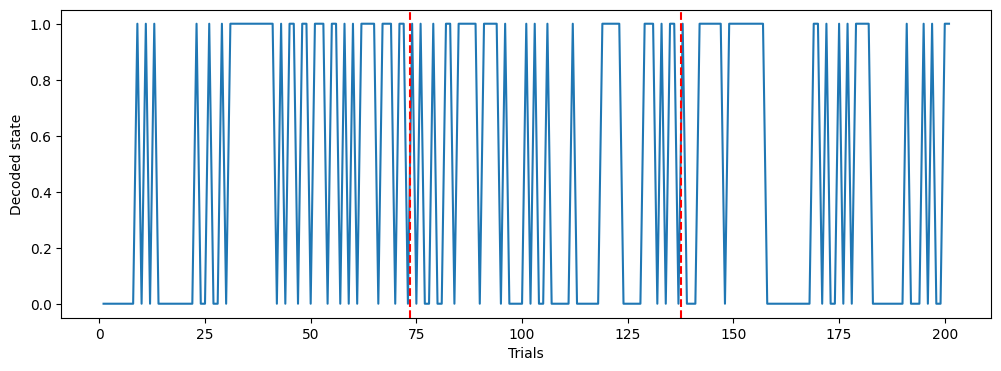

In [58]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(trial_states["state"].to_numpy())

changes = np.flatnonzero(
    trial_states["block_idx"].to_numpy()[1:]
    != trial_states["block_idx"].to_numpy()[:-1]
) + 1

for i in changes:
    ax.axvline(i - 0.5, color="red", linestyle="--")
    
# for i in np.flatnonzero(trial_states["trial_type"].to_numpy() == 'b'):
#     ax.axvline(i, color="green", linestyle="--")

ax.set(xlabel="Trials", ylabel="Decoded state")
plt.show()

In [18]:
# recording
import pynapple as nap

context_by_trial = recording['context_by_trial']

context_intervals = nap.IntervalSet(
    pd.DataFrame(
        {
            "start": recording["trial_starts"],
            "end": recording["trial_ends"],
            "context": context_by_trial,
        }
    )
)

position = nap.Tsd(
    t=recording["position_times"], 
    d=recording["position_values"]
    )

context_tsd = nap.Tsd(
    t = position.t,
    d = context_by_trial[
        pd.Series(
            context_intervals.in_interval(position)
            ).ffill().bfill().astype(int).to_numpy()
        ]
    )


KeyError: 'context_by_trial is not a file in the archive'

In [48]:
context_tsd

Time (s)
----------  --
0.0          1
0.001        1
0.002        1
0.003        1
0.004        1
0.005        1
0.006        1
...
1821.382     0
1821.383     0
1821.384     0
1821.385     0
1821.386     0
1821.387     0
1821.388     0
dtype: int64, shape: (1821389,)

In [50]:
context_intervals

index    start     end       context
0        0.0       0.976     1
1        0.994     7.845     1
2        7.858     12.843    1
3        12.858    19.66     1
4        19.676    25.11     1
5        25.129    29.978    1
6        29.993    35.028    0
...      ...       ...       ...
205      1751.106  1764.237  1
206      1764.257  1772.909  1
207      1772.921  1782.342  1
208      1782.355  1795.926  1
209      1795.94   1802.106  1
210      1802.122  1813.375  0
211      1813.39   1821.388  0
shape: (212, 2), time unit: sec.

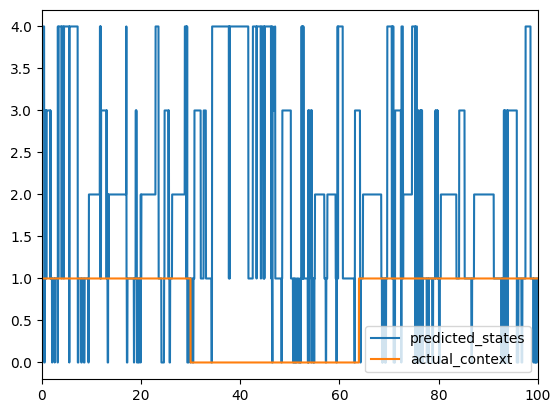

In [47]:
plt.plot(t, predicted_states, label='predicted_states')
plt.plot(context_tsd, label='actual_context')
plt.plot()
plt.xlim(0,100)
plt.legend()

In [54]:
# Use the timestamps of the spike-count bins used by the GLM-HMM.
# Replace y.times() with your actual model-bin timestamps if necessary.

predicted_state_tsd = nap.Tsd(
    t=t,
    d=np.asarray(predicted_states).astype(int),
)

In [54]:
predicted_state_tsd

Time (s)
--------------------  --
0.018866666666666667   4
0.038866667            4
0.058866667000000004   4
0.078866667            4
0.09886666699999999    4
0.118866667            4
0.138866667            4
...
1821.198866667         2
1821.218866667         2
1821.238866667         2
1821.258866667         2
1821.278866667         2
1821.298866667         2
1821.318866667         2
dtype: int64, shape: (91066,)

In [55]:
def calculate_state_ratio_by_context_block(
    predicted_state_tsd,
    context_intervals,
    n_states=None,
):
    """
    Calculate the proportion of decoded states in each consecutive
    block of trials belonging to the same context.

    Inter-trial gaps are excluded.
    """

    trials = context_intervals.as_dataframe().reset_index(drop=True).copy()

    required = ["start", "end", "context"]

    missing = [
        column
        for column in required
        if column not in trials.columns
    ]

    if missing:
        raise ValueError(
            f"Context IntervalSet is missing columns: {missing}"
        )

    trials = trials.sort_values("start").reset_index(drop=True)
    trials["context"] = trials["context"].astype(int)
    trials["trial_index"] = np.arange(len(trials))

    # A new block begins whenever context changes
    trials["block_order"] = (
        trials["context"]
        .ne(trials["context"].shift())
        .cumsum()
        - 1
    )

    block_information = (
        trials.groupby("block_order", as_index=False)
        .agg(
            context=("context", "first"),
            trial_idx_start=("trial_index", "min"),
            trial_idx_end=("trial_index", "max"),
            n_trials=("trial_index", "size"),
            block_start=("start", "min"),
            block_end=("end", "max"),
        )
    )

    # Number each appearance of context 0 and context 1 separately
    block_information["context_repetition"] = (
        block_information.groupby("context").cumcount() + 1
    )

    state_values = np.asarray(
        predicted_state_tsd.values
    ).astype(int).ravel()

    if n_states is None:
        n_states = int(state_values.max()) + 1

    result_rows = []

    for block_order, block_trials in trials.groupby("block_order"):
        context = int(block_trials["context"].iloc[0])

        context_repetition = int(
            block_information.loc[
                block_information["block_order"].eq(block_order),
                "context_repetition",
            ].iloc[0]
        )

        # Construct an IntervalSet containing every trial in this block.
        # Because each trial is a separate interval, inter-trial gaps
        # are not included.
        block_epochs = nap.IntervalSet(
            start=block_trials["start"].to_numpy(),
            end=block_trials["end"].to_numpy(),
        )

        block_states = np.asarray(
            predicted_state_tsd.restrict(block_epochs).values
        ).astype(int).ravel()

        if len(block_states) == 0:
            ratios = np.full(n_states, np.nan)
            counts = np.zeros(n_states, dtype=int)
        else:
            counts = np.bincount(
                block_states,
                minlength=n_states,
            )

            ratios = counts / counts.sum()

        row = {
            "block_order": int(block_order),
            "context": context,
            "context_repetition": context_repetition,
            "trial_idx_start": int(block_trials["trial_index"].min()),
            "trial_idx_end": int(block_trials["trial_index"].max()),
            "n_trials": len(block_trials),
            "n_state_bins": len(block_states),
        }

        for state in range(n_states):
            row[f"n_state_{state}"] = counts[state]
            row[f"r_state_{state}"] = ratios[state]

        if np.all(np.isnan(ratios)):
            row["dominant_state"] = np.nan
        else:
            row["dominant_state"] = int(np.nanargmax(ratios))

        result_rows.append(row)

    block_state_ratios = pd.DataFrame(result_rows)

    return block_state_ratios, trials

In [56]:
block_state_ratios, trial_table = (
    calculate_state_ratio_by_context_block(
        predicted_state_tsd=predicted_state_tsd,
        context_intervals=context_intervals,
        n_states=None,
    )
)

In [57]:
block_state_ratios

,block_order,context,context_repetition,trial_idx_start,trial_idx_end,n_trials,n_state_bins,n_state_0,r_state_0,n_state_1,r_state_1,n_state_2,r_state_2,n_state_3,r_state_3,n_state_4,r_state_4,dominant_state
0,0,1,1,0,5,6,1496,119,0.079545,386,0.258021,564,0.377005,155,0.103610,272,0.181818,2
1,1,0,1,6,11,6,1694,96,0.056671,557,0.328808,179,0.105667,262,0.154664,600,0.354191,4
2,2,1,2,12,17,6,2181,155,0.071068,651,0.298487,699,0.320495,340,0.155892,336,0.154058,2
3,3,0,2,18,23,6,1971,121,0.061390,500,0.253678,282,0.143075,651,0.330289,417,0.211568,3
4,4,1,3,24,29,6,2155,99,0.045940,521,0.241763,1024,0.475174,168,0.077958,343,0.159165,2
5,5,0,3,30,35,6,2018,57,0.028246,294,0.145689,880,0.436075,187,0.092666,600,0.297324,2
6,6,1,4,36,41,6,2328,126,0.054124,743,0.319158,583,0.250430,470,0.201890,406,0.174399,1
7,7,0,4,42,47,6,2117,62,0.029287,409,0.193198,736,0.347662,378,0.178555,532,0.251299,2
8,8,1,5,48,53,6,2208,118,0.053442,525,0.237772,990,0.448370,144,0.065217,431,0.195199,2
9,9,0,5,54,59,6,2099,74,0.035255,503,0.239638,352,0.167699,511,0.243449,659,0.313959,4


In [59]:
def plot_state_ratios_by_context_block(
    block_state_ratios,
    sort_by_context=True,
    context_order=(0, 1),
    figsize=(17, 6),
):
    """
    Plot state occupancy ratios.

    If sort_by_context=True:
        Group blocks by context and order by context repetition.

    If sort_by_context=False:
        Preserve the original chronological block order.
    """

    ratio_columns = [
        column
        for column in block_state_ratios.columns
        if column.startswith("r_state_")
    ]

    state_numbers = [
        int(column.replace("r_state_", ""))
        for column in ratio_columns
    ]

    plot_data = block_state_ratios.copy()

    if sort_by_context:
        plot_data["context"] = pd.Categorical(
            plot_data["context"],
            categories=context_order,
            ordered=True,
        )

        plot_data = (
            plot_data
            .sort_values(
                ["context", "context_repetition"]
            )
            .reset_index(drop=True)
        )

    else:
        # Restore chronological context-block order
        plot_data = (
            plot_data
            .sort_values("block_order")
            .reset_index(drop=True)
        )

    x = np.arange(len(plot_data))
    bottom = np.zeros(len(plot_data))

    colours = ['#ffffcc', '#c2e699', '#78c679', '#31a354', '#006837']

    fig, ax = plt.subplots(figsize=figsize)

    for column, state, colour in zip(
        ratio_columns,
        state_numbers,
        colours,
    ):
        values = plot_data[column].fillna(0).to_numpy()

        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.85,
            color=colour,
            label=f"State {state}",
        )

        bottom += values

    if sort_by_context:
        labels = [
            f"{int(repetition)}"
            for repetition in plot_data["context_repetition"]
        ]
    else:
        labels = [
            f"C{int(context)}–R{int(repetition)}"
            for context, repetition in zip(
                plot_data["context"],
                plot_data["context_repetition"],
            )
        ]

    ax.set_xticks(x)
    ax.set_xticklabels(
        labels,
        # rotation=45,
        # ha="right",
    )

    if sort_by_context:
        context_groups = plot_data.groupby(
            "context",
            observed=True,
            sort=False,
        )

        for group_number, (context, group) in enumerate(context_groups):
            positions = group.index.to_numpy()
            first = positions.min()
            last = positions.max()
            centre = (first + last) / 2

            ax.text(
                centre,
                1.02,
                f"Context {context}",
                ha="center",
                va="bottom",
                fontsize=20,
            )

            if group_number < len(context_order) - 1:
                ax.axvline(
                    last + 0.5,
                    color="black",
                    linewidth=4,
                    linestyle="-",
                    alpha=1,
                )

    else:
        # Mark every chronological context transition
        contexts = plot_data["context"].astype(int).to_numpy()

        for index in range(1, len(contexts)):
            if contexts[index] != contexts[index - 1]:
                ax.axvline(
                    index - 0.5,
                    color="black",
                    linewidth=0.7,
                    alpha=0.3,
                )

    ax.set_xlim(-0.6, len(plot_data) - 0.4)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', labelsize=15)
    ax.tick_params(axis='y', labelsize=18)

    ax.set_ylabel("Hidden state ratio", fontsize=20)
    ax.set_xlabel(
        "Number of same context repetition"
        if sort_by_context
        else "Context block in chronological order",
        fontsize=20
    )
    

    ax.legend(
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=20
    )

    fig.tight_layout()

    return fig, ax

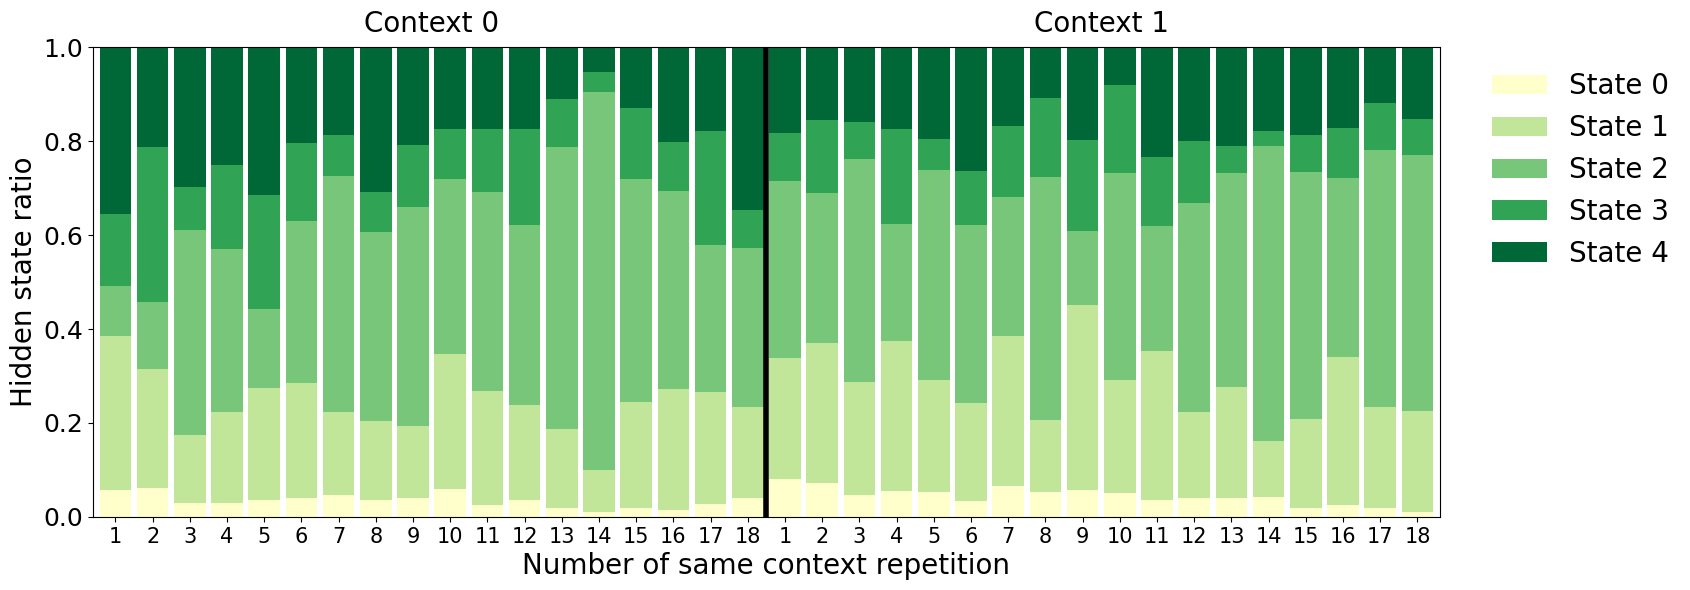

In [60]:
fig, ax = plot_state_ratios_by_context_block(
    block_state_ratios,
    sort_by_context=True,
    context_order=(0, 1),
)

plt.savefig('1st_year_report/glm_hmm_state_context.png', dpi=400)

In [65]:
def test_dominant_states(block_state_ratios):
    """
    Test whether state occupancy ratios differ within each context.

    The statistical unit is a context block, not an individual
    model time bin.
    """

    ratio_columns = [
        column
        for column in block_state_ratios.columns
        if column.startswith("r_state_")
    ]

    state_numbers = [
        int(column.replace("r_state_", ""))
        for column in ratio_columns
    ]

    omnibus_results = []
    pairwise_results = []

    for context, context_data in block_state_ratios.groupby("context"):
        ratios = context_data[ratio_columns].dropna()

        mean_ratios = ratios.mean()

        dominant_column = mean_ratios.idxmax()
        dominant_state = int(
            dominant_column.replace("r_state_", "")
        )

        if len(ratios) < 3:
            print(
                f"Context {context}: fewer than three valid blocks; "
                "no test performed."
            )
            continue

        # Omnibus or two-state test
        if len(ratio_columns) == 2:
            statistic, p_value = wilcoxon(
                ratios[ratio_columns[0]],
                ratios[ratio_columns[1]],
                alternative="two-sided",
                zero_method="zsplit",
            )

            test_name = "Wilcoxon signed-rank"

        else:
            statistic, p_value = friedmanchisquare(
                *[
                    ratios[column].to_numpy()
                    for column in ratio_columns
                ]
            )

            test_name = "Friedman"

        omnibus_results.append(
            {
                "context": context,
                "n_blocks": len(ratios),
                "test": test_name,
                "statistic": statistic,
                "p_value": p_value,
                "dominant_state": dominant_state,
                "dominant_mean_ratio": mean_ratios[
                    dominant_column
                ],
            }
        )

        # All pairwise state comparisons
        context_pairwise = []

        for index_1 in range(len(ratio_columns)):
            for index_2 in range(index_1 + 1, len(ratio_columns)):
                column_1 = ratio_columns[index_1]
                column_2 = ratio_columns[index_2]

                statistic, pair_p = wilcoxon(
                    ratios[column_1],
                    ratios[column_2],
                    alternative="two-sided",
                    zero_method="zsplit",
                )

                context_pairwise.append(
                    {
                        "context": context,
                        "state_1": state_numbers[index_1],
                        "state_2": state_numbers[index_2],
                        "mean_ratio_1": ratios[column_1].mean(),
                        "mean_ratio_2": ratios[column_2].mean(),
                        "statistic": statistic,
                        "p_value": pair_p,
                    }
                )

        context_pairwise = pd.DataFrame(context_pairwise)

        context_pairwise["p_adjusted"] = multipletests(
            context_pairwise["p_value"],
            method="holm",
        )[1]

        context_pairwise["significant"] = (
            context_pairwise["p_adjusted"] < 0.05
        )

        pairwise_results.append(context_pairwise)

    omnibus_results = pd.DataFrame(omnibus_results)

    pairwise_results = pd.concat(
        pairwise_results,
        ignore_index=True,
    )

    # Correct the omnibus tests across contexts
    if not omnibus_results.empty:
        omnibus_results["p_adjusted"] = multipletests(
            omnibus_results["p_value"],
            method="holm",
        )[1]

        omnibus_results["significant"] = (
            omnibus_results["p_adjusted"] < 0.05
        )

    return omnibus_results, pairwise_results

In [66]:
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests

omnibus_results, pairwise_state_results = (
    test_dominant_states(block_state_ratios)
)

print("\nOmnibus tests:")
print(omnibus_results.to_string(index=False))

print("\nPairwise state comparisons:")
print(pairwise_state_results.to_string(index=False))


Omnibus tests:
 context  n_blocks     test  statistic      p_value  dominant_state  dominant_mean_ratio   p_adjusted  significant
       0        18 Friedman  48.133333 8.852706e-10               2             0.391954 8.852706e-10         True
       1        18 Friedman  58.177778 7.002647e-12               2             0.414410 1.400529e-11         True

Pairwise state comparisons:
 context  state_1  state_2  mean_ratio_1  mean_ratio_2  statistic  p_value  p_adjusted  significant
       0        0        1      0.034580      0.211484        0.0 0.000008    0.000076         True
       0        0        2      0.034580      0.391954        0.0 0.000008    0.000076         True
       0        0        3      0.034580      0.146760        0.0 0.000008    0.000076         True
       0        0        4      0.034580      0.215222        0.0 0.000008    0.000076         True
       0        1        2      0.211484      0.391954       17.0 0.001579    0.006447         True
       0  

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from patsy import build_design_matrices
from scipy.stats import chi2, norm
from statsmodels.stats.multitest import multipletests


csv_path = Path(
    "/Users/zhaoyiming/ephys_analysis/ramps_stats/"
    "ramps_classification.csv"
)

df = pd.read_csv(csv_path)

# ============================================================
# Restrict data
# ============================================================

restricted_df = df[
    df["task_type"].eq("standard_track")
    & df["trial_type"].eq(0)
].copy()

ramp_subtypes = [
    "--",
    "-+",
    "++",
    "+-",
]

# Mouse labels repeat between experimenters in this CSV, so "mouse"
# alone is not a unique identifier.
restricted_df["mouse_id"] = (
    restricted_df["experimenter"].astype(str)
    + "_"
    + restricted_df["mouse"].astype(str)
)

# Check that each mouse has only one genotype
genotypes_per_mouse = (
    restricted_df
    .groupby("mouse_id")["genotype"]
    .nunique()
)

if (genotypes_per_mouse > 1).any():
    raise ValueError(
        "At least one mouse_id is associated with multiple genotypes."
    )

# ============================================================
# Calculate subtype ratios for each mouse
# ============================================================

# Denominator: all eligible cells from each mouse
total_cells = (
    restricted_df
    .groupby(["mouse_id", "genotype"])
    .size()
    .rename("n_total_cells")
)

# Numerator: cells belonging to each requested subtype
subtype_counts = (
    restricted_df[
        restricted_df["ramp_type"].isin(ramp_subtypes)
    ]
    .groupby(
        ["mouse_id", "genotype", "ramp_type"]
    )
    .size()
    .unstack(fill_value=0)
)

# Add missing subtypes and mice as zeros
subtype_counts = subtype_counts.reindex(
    index=total_cells.index,
    columns=ramp_subtypes,
    fill_value=0,
)

subtype_ratios = subtype_counts.div(
    total_cells,
    axis=0,
)

# Convert to long format for the mixed model
ratio_df = (
    subtype_ratios
    .reset_index()
    .melt(
        id_vars=["mouse_id", "genotype"],
        value_vars=ramp_subtypes,
        var_name="ramp_type",
        value_name="ratio",
    )
    .reset_index(drop=True)
)

ratio_df["genotype"] = pd.Categorical(
    ratio_df["genotype"],
    categories=["FXS", "WT"],
)

ratio_df["ramp_type"] = pd.Categorical(
    ratio_df["ramp_type"],
    categories=ramp_subtypes,
)

print("Mouse-level subtype ratios:")
print(
    ratio_df.sort_values(
        ["mouse_id", "ramp_type"]
    ).to_string(index=False)
)

# ============================================================
# Linear mixed-effects model
# ============================================================

model = smf.mixedlm(
    formula=(
        "ratio ~ C(genotype) * C(ramp_type)"
    ),
    data=ratio_df,
    groups="mouse_id",
    re_formula="1",
)

result = model.fit(
    reml=False,
    method="lbfgs",
    maxiter=2000,
    disp=False,
)

print("\nMixed-model summary:")
print(result.summary())

Mouse-level subtype ratios:
 mouse_id genotype ramp_type    ratio
 Junji_M1       WT        -- 0.008621
 Junji_M1       WT        -+ 0.034483
 Junji_M1       WT        ++ 0.000000
 Junji_M1       WT        +- 0.008621
Junji_M10       WT        -- 0.052632
Junji_M10       WT        -+ 0.010526
Junji_M10       WT        ++ 0.084211
Junji_M10       WT        +- 0.047368
 Junji_M2      FXS        -- 0.137931
 Junji_M2      FXS        -+ 0.072797
 Junji_M2      FXS        ++ 0.061303
 Junji_M2      FXS        +- 0.049808
 Junji_M3      FXS        -- 0.065217
 Junji_M3      FXS        -+ 0.000000
 Junji_M3      FXS        ++ 0.021739
 Junji_M3      FXS        +- 0.021739
 Junji_M4      FXS        -- 0.207547
 Junji_M4      FXS        -+ 0.025157
 Junji_M4      FXS        ++ 0.034591
 Junji_M4      FXS        +- 0.069182
 Junji_M5       WT        -- 0.072464
 Junji_M5       WT        -+ 0.036232
 Junji_M5       WT        ++ 0.050725
 Junji_M5       WT        +- 0.007246
 Junji_M6       WT    

/Users/zhaoyiming/pynapple_env_312/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/zhaoyiming/pynapple_env_312/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [117]:
result.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                     Mixed Linear Model Regression Results
===============================================================================
Model:                     MixedLM         Dependent Variable:         ratio   
No. Observations:          80              Method:                     ML      
No. Groups:                20              Scale:                      0.0009  
Min. group size:           4               Log-Likelihood:             159.7091
Max. group size:           4               Converged:                  Yes     
Mean group size:           4.0                                                 
-------------------------------------------------------------------------------
                                     Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------------------------
Intercept                             0.065    0.011  6.015 0.000  0.044  0.086
C(genotype)[T.WT]                    -0.029    0.015 -1.916 0.055 -0.059  0.001
C(ramp_type)[T.-+]                   -0.033    0.013 -2.492 0.013 -0.059 -0.007
C(ramp_type)[T.++]                   -0.020    0.013 -1.507 0.132 -0.046  0.006
C(ramp_type)[T.+-]                   -0.036    0.013 -2.734 0.006 -0.063 -0.010
C(genotype)[T.WT]:C(ramp_type)[T.-+]  0.032    0.019  1.696 0.090 -0.005  0.069
C(genotype)[T.WT]:C(ramp_type)[T.++]  0.026    0.019  1.357 0.175 -0.011  0.063
C(genotype)[T.WT]:C(ramp_type)[T.+-]  0.027    0.019  1.413 0.158 -0.010  0.064
mouse_id Var                          0.000    0.006                           
===============================================================================

"""

In [2]:
fixed_names = list(result.fe_params.index)
beta = result.fe_params.to_numpy()

fixed_covariance = (
    result.cov_params()
    .loc[fixed_names, fixed_names]
    .to_numpy()
)

design_info = model.data.design_info


def fixed_design_row(genotype, ramp_type):
    return np.asarray(
        build_design_matrices(
            [design_info],
            {
                "genotype": [genotype],
                "ramp_type": [ramp_type],
            },
        )[0]
    )[0]


# WT minus FXS contrast for each subtype
contrast_matrix = np.vstack(
    [
        fixed_design_row("WT", subtype)
        - fixed_design_row("FXS", subtype)
        for subtype in ramp_subtypes
    ]
)

differences = contrast_matrix @ beta

difference_covariance = (
    contrast_matrix
    @ fixed_covariance
    @ contrast_matrix.T
)

wald_statistic = (
    differences.T
    @ np.linalg.pinv(difference_covariance)
    @ differences
)

wald_df = np.linalg.matrix_rank(contrast_matrix)
overall_p = chi2.sf(wald_statistic, df=wald_df)

print("\nOverall genotype test across four subtypes:")
print(
    f"Wald chi-square({wald_df}) = "
    f"{wald_statistic:.3f}, p = {overall_p:.4g}"
)


Overall genotype test across four subtypes:
Wald chi-square(4) = 4.119, p = 0.3901


/var/folders/xb/w541y92n6v13hd1kqsvs2df00000gn/T/ipykernel_74373/855494694.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/xb/w541y92n6v13hd1kqsvs2df00000gn/T/ipykernel_74373/855494694.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["FXS", "WT"], fontsize=18)
/var/folders/xb/w541y92n6v13hd1kqsvs2df00000gn/T/ipykernel_74373/855494694.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(
/var/folders/xb/w541y92n6v13hd1kqsvs2df00000gn/T/ipykernel_74373/855494694.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and se

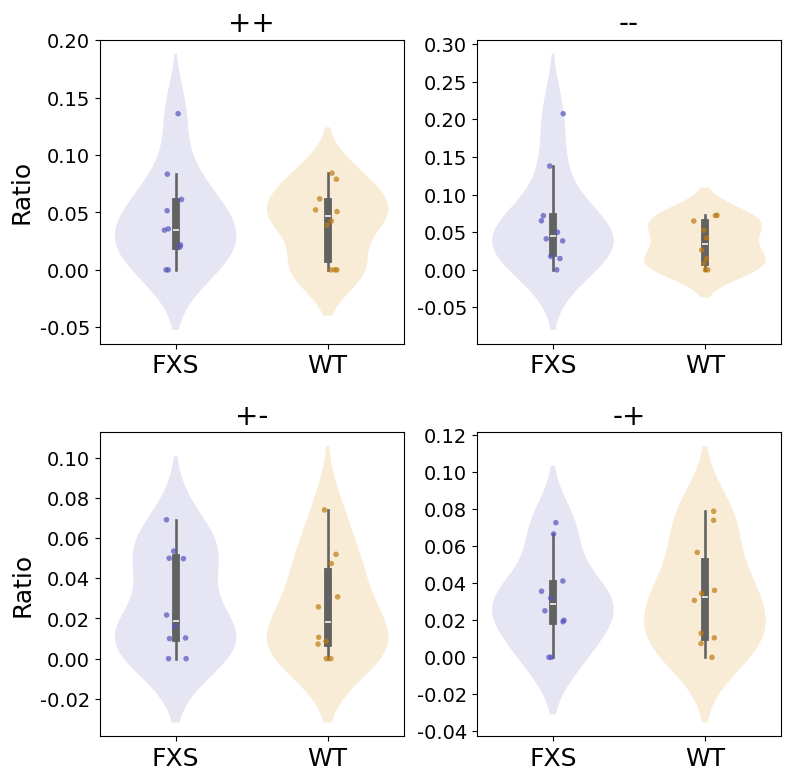

In [42]:
from matplotlib.collections import PolyCollection

ramp_subtypes = ["++", "--", "+-", "-+"]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(8, 8),
)

axes = axes.ravel()

for ax, ramp in zip(axes, ramp_subtypes):
    ax.set_box_aspect(1)
    temp_df = ratio_df[
        ratio_df["ramp_type"] == ramp
    ].copy()

    sns.violinplot(
        data=temp_df,
        x="genotype",
        y="ratio",
        order=["FXS", "WT"],
        palette=["#8E8EE0", "#FCB94B"],
        ax=ax,
        alpha=0.25,
    )
    
    for collection in ax.collections:
        if isinstance(collection, PolyCollection):
            collection.set_edgecolor("none")

    sns.stripplot(
        data=temp_df,
        x="genotype",
        y="ratio",
        order=["FXS", "WT"],
        hue="genotype",
        palette=["#5454BE", "#BD7A0E"],
        size=4,
        alpha=0.7,
        jitter=0.08,
        ax=ax,  
    )

    ax.set_title(ramp, fontsize=20)
    ax.set_xlabel("")
    ax.set_xticklabels(["FXS", "WT"], fontsize=18)
    ax.set_yticklabels(
        [f"{tick:.2f}" for tick in ax.get_yticks()],
        fontsize=14,
    )

    # Show y-axis label only on the left column
    if ax in [axes[0], axes[2]]:
        ax.set_ylabel("Ratio", fontsize=18)
    else:
        ax.set_ylabel("")

fig.tight_layout()
plt.savefig('1st_year_report/ramps_subtype_ratios.png', dpi=400)